<a href="https://colab.research.google.com/github/BuvanAlfarezy/BuvanAlfarezy_Test2_KlasifikasiCNN/blob/main/BuvanAlfarezy_Test2_KlasifikasiCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
from collections import defaultdict, Counter
import json
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, UnidentifiedImageError

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "OceanicLife Dataset"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 160
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 3e-4


LABEL_CSV = None
IMAGE_COLUMN = None
LABEL_COLUMN = None
SPLIT_COLUMN = None

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp", ".tif", ".tiff"}
SPLIT_ALIASES = {
    "train": "train", "training": "train",
    "val": "validation", "valid": "validation", "validation": "validation",
    "test": "test", "testing": "test",
}

print("Folder proyek :", PROJECT_DIR)
print("Folder dataset:", DATASET_DIR.resolve())
print("TensorFlow    :", tf.__version__)
print("GPU terdeteksi:", tf.config.list_physical_devices("GPU"))

Folder proyek : d:\Tugas Analisis Big Data\2
Folder dataset: D:\Tugas Analisis Big Data\2\OceanicLife Dataset
TensorFlow    : 2.21.0
GPU terdeteksi: []


In [ ]:
if not DATASET_DIR.exists():
    possible_paths = [
        PROJECT_DIR / "dataset" / "OceanicLife Dataset",
        PROJECT_DIR / "data" / "OceanicLife Dataset",
        PROJECT_DIR / "Oceanic_Life-Dataset",
    ]
    found = next((p for p in possible_paths if p.exists()), None)
    if found is not None:
        DATASET_DIR = found
    else:
        raise FileNotFoundError(
            "Folder dataset tidak ditemukan. Letakkan folder 'OceanicLife Dataset' "
            "di samping notebook atau ubah DATASET_DIR pada cell konfigurasi.\n"
            f"Lokasi yang diperiksa: {DATASET_DIR.resolve()}"
        )

IMAGE_PATHS = sorted(
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)
CSV_FILES = sorted(set(DATASET_DIR.rglob("*.csv")) | set(DATASET_DIR.glob("*.CSV")))

CSV_FILES += [p for p in DATASET_DIR.parent.glob("*.csv") if p not in CSV_FILES]

print(f"Jumlah file gambar ditemukan: {len(IMAGE_PATHS):,}")
print(f"Jumlah file CSV ditemukan   : {len(CSV_FILES)}")
print("\nContoh path gambar:")
for p in IMAGE_PATHS[:10]:
    print(" -", p.relative_to(DATASET_DIR))

if CSV_FILES:
    print("\nFile CSV yang ditemukan:")
    for p in CSV_FILES[:20]:
        print(" -", p)
if not IMAGE_PATHS:
    raise RuntimeError("Tidak ada gambar yang dikenali. Periksa kembali DATASET_DIR dan format file.")

Jumlah file gambar ditemukan: 7,990
Jumlah file CSV ditemukan   : 0

Contoh path gambar:
 - 001v5h0d.jpg
 - 002ojjl6.jpg
 - 00dx9zud.JPG
 - 00gohyw5.jpg
 - 00lvn4tu.gif
 - 015e0ase.jpg
 - 015us06k.jpg
 - 017s6334.jpeg
 - 01cqbman.jpg
 - 01fifu6i.jpg


In [ ]:
def _norm_col(value):
    return "".join(ch.lower() for ch in str(value) if ch.isalnum())

IMAGE_COL_HINTS = ["filepath", "imagepath", "path", "filename", "file_name", "image", "file", "imagename", "imageid"]
LABEL_COL_HINTS = ["label", "class", "category", "species", "organism", "target", "class_name", "type"]
SPLIT_COL_HINTS = ["split", "subset", "set", "partition"]


def _choose_column(columns, hints):
    normed = {_norm_col(col): col for col in columns}
    for hint in hints:
        if _norm_col(hint) in normed:
            return normed[_norm_col(hint)]
    for col in columns:
        n = _norm_col(col)
        if any(_norm_col(hint) in n for hint in hints):
            return col
    return None



_IMAGE_BY_NAME = defaultdict(list)
_IMAGE_BY_STEM = defaultdict(list)
for _image_path in IMAGE_PATHS:
    _IMAGE_BY_NAME[_image_path.name.lower()].append(_image_path)
    _IMAGE_BY_STEM[_image_path.stem.lower()].append(_image_path)


def _resolve_csv_path(value, image_paths, root):
    if pd.isna(value):
        return None
    raw = str(value).strip().strip('"').strip("'")
    if not raw or raw.lower() in {"nan", "none", "null"}:
        return None

    p = Path(raw)
    candidates = []
    if p.is_absolute():
        candidates.append(p)
    else:
        candidates.extend([root / raw, root / raw.replace("\\", "/")])
    for candidate in candidates:
        try:
            if candidate.is_file() and candidate.suffix.lower() in IMAGE_EXTENSIONS:
                return str(candidate.resolve())
        except OSError:
            pass

    basename = Path(raw.replace("\\", "/")).name.lower()
    matches = _IMAGE_BY_NAME.get(basename, [])
    if not matches and not Path(basename).suffix:
        matches = _IMAGE_BY_STEM.get(basename, [])
    if len(matches) == 1:
        return str(matches[0].resolve())
    return None


def _infer_folder_rows(image_paths, root):

    split_rows = []
    for path in image_paths:
        rel = path.relative_to(root)
        parts = rel.parts
        if len(parts) >= 3 and parts[0].lower() in SPLIT_ALIASES:
            split_name = SPLIT_ALIASES[parts[0].lower()]
            class_name = parts[1].strip()
            if class_name:
                split_rows.append({"filepath": str(path.resolve()), "label": class_name, "split": split_name})
    if split_rows and len({row["label"] for row in split_rows}) >= 2:
        return pd.DataFrame(split_rows), "folder split/kelas"


    groups = defaultdict(lambda: defaultdict(list))
    depths = {}
    for path in image_paths:
        rel = path.relative_to(root)
        parent_parts = rel.parts[:-1]
        if not parent_parts:
            continue
        group_key = (len(parent_parts), tuple(parent_parts[:-1]))
        class_name = parent_parts[-1].strip()
        groups[group_key][class_name].append(path)
        depths[group_key] = len(parent_parts)

    candidates = []
    for group_key, class_map in groups.items():
        if len(class_map) >= 2:
            total_images = sum(len(paths) for paths in class_map.values())
            candidates.append((len(class_map), total_images, -depths[group_key], group_key, class_map))
    if not candidates:
        return None, None


    _, _, _, _, best_map = max(candidates, key=lambda item: (item[0], item[1], item[2]))
    rows = []
    for class_name, paths in best_map.items():
        for path in paths:
            rows.append({"filepath": str(path.resolve()), "label": class_name})
    result = pd.DataFrame(rows).drop_duplicates(subset=["filepath"])
    return result, "folder kelas"


def _try_metadata_csv(csv_files, image_paths, root):
    chosen_path = None
    chosen_image_col = IMAGE_COLUMN
    chosen_label_col = LABEL_COLUMN
    chosen_split_col = SPLIT_COLUMN

    if LABEL_CSV:
        csv_path = Path(LABEL_CSV)
        if not csv_path.is_absolute():
            csv_path = (PROJECT_DIR / csv_path).resolve()
        if not csv_path.exists():
            candidate = (root / LABEL_CSV).resolve()
            if candidate.exists():
                csv_path = candidate
            else:
                raise FileNotFoundError(f"LABEL_CSV tidak ditemukan: {LABEL_CSV}")
        chosen_path = csv_path
    else:
        for csv_path in csv_files:
            try:
                preview = pd.read_csv(csv_path, nrows=5)
            except Exception:
                continue
            image_col = chosen_image_col or _choose_column(preview.columns, IMAGE_COL_HINTS)
            label_col = chosen_label_col or _choose_column(preview.columns, LABEL_COL_HINTS)
            if image_col in preview.columns and label_col in preview.columns and image_col != label_col:
                chosen_path = csv_path
                chosen_image_col = image_col
                chosen_label_col = label_col
                if not chosen_split_col:
                    chosen_split_col = _choose_column(preview.columns, SPLIT_COL_HINTS)
                break

    if chosen_path is None:
        return None, None

    table = pd.read_csv(chosen_path)
    if chosen_image_col not in table.columns:
        chosen_image_col = None
    if chosen_label_col not in table.columns:
        chosen_label_col = None
    if chosen_split_col not in table.columns:
        chosen_split_col = None
    chosen_image_col = chosen_image_col or _choose_column(table.columns, IMAGE_COL_HINTS)
    chosen_label_col = chosen_label_col or _choose_column(table.columns, LABEL_COL_HINTS)
    chosen_split_col = chosen_split_col or _choose_column(table.columns, SPLIT_COL_HINTS)
    if not chosen_image_col or not chosen_label_col:
        print(f"CSV {chosen_path.name} ditemukan, tetapi kolom gambar/label tidak teridentifikasi.")
        print("Kolom yang tersedia:", list(table.columns))
        print("Isi IMAGE_COLUMN dan LABEL_COLUMN di cell konfigurasi, lalu jalankan ulang cell ini.")
        return None, None

    rows = []
    for _, row in table.iterrows():
        filepath = _resolve_csv_path(row[chosen_image_col], image_paths, root)
        label = row[chosen_label_col]
        if filepath and not pd.isna(label) and str(label).strip():
            item = {"filepath": filepath, "label": str(label).strip()}
            if chosen_split_col and chosen_split_col in table.columns and not pd.isna(row[chosen_split_col]):
                raw_split = str(row[chosen_split_col]).strip().lower()
                item["split"] = SPLIT_ALIASES.get(raw_split, raw_split)
            rows.append(item)

    if not rows:
        print(f"CSV {chosen_path.name} terbaca, tetapi tidak ada path gambar yang cocok dengan file dataset.")
        return None, None
    result = pd.DataFrame(rows)

    conflicts = result.groupby("filepath")["label"].nunique()
    conflict_paths = set(conflicts[conflicts > 1].index)
    if conflict_paths:
        print(f"Peringatan: {len(conflict_paths)} gambar memiliki label yang bertentangan; baris tersebut dibuang.")
        result = result[~result["filepath"].isin(conflict_paths)]
    result = result.drop_duplicates(subset=["filepath"])
    return result, f"CSV: {chosen_path.name}"


metadata_df, metadata_source = _try_metadata_csv(CSV_FILES, IMAGE_PATHS, DATASET_DIR)
if metadata_df is not None and metadata_df["label"].nunique() >= 2:
    df = metadata_df.copy()
    label_source = metadata_source
else:
    folder_df, folder_source = _infer_folder_rows(IMAGE_PATHS, DATASET_DIR)
    if folder_df is not None and folder_df["label"].nunique() >= 2:
        df = folder_df.copy()
        label_source = folder_source
    else:
        df = pd.DataFrame({"filepath": [str(p.resolve()) for p in IMAGE_PATHS]})
        label_source = None

LABELS_AVAILABLE = label_source is not None and "label" in df.columns and df["label"].nunique() >= 2
print("Sumber label:", label_source if LABELS_AVAILABLE else "BELUM DITEMUKAN")
print("Jumlah gambar dengan label:", f"{len(df):,}" if LABELS_AVAILABLE else "belum tersedia")
if LABELS_AVAILABLE:
    print("Jumlah kelas:", df["label"].nunique())
    display(df.head())
    print("\nJumlah gambar per label (5 teratas):")
    display(df["label"].value_counts().head())
else:
    print("Notebook menemukan gambar, tetapi belum menemukan label kelas yang bisa dipakai.")
    print("Periksa apakah dataset mempunyai CSV label atau folder untuk setiap kelas.")
    print("Kalau CSV label tersedia, isi LABEL_CSV, IMAGE_COLUMN, dan LABEL_COLUMN di cell konfigurasi.")
    print("Jangan lanjutkan klaim evaluasi CNN sebelum label yang benar tersedia.")

Sumber label: BELUM DITEMUKAN
Jumlah gambar dengan label: belum tersedia
Notebook menemukan gambar, tetapi belum menemukan label kelas yang bisa dipakai.
Periksa apakah dataset mempunyai CSV label atau folder untuk setiap kelas.
Kalau CSV label tersedia, isi LABEL_CSV, IMAGE_COLUMN, dan LABEL_COLUMN di cell konfigurasi.
Jangan lanjutkan klaim evaluasi CNN sebelum label yang benar tersedia.


In [ ]:
AUTO_LABEL_CSV = ARTIFACTS_DIR / "labels_auto_review.csv"
AUTO_CLASS_PROMPTS = {
    "Fish": "an underwater photograph whose main subject is a fish other than a shark",
    "Coral": "an underwater photograph whose main subject is coral or a coral colony",
    "Shark": "an underwater photograph whose main subject is a shark",
    "Octopus": "an underwater photograph whose main subject is an octopus",
    "Crustaceans": "an underwater photograph whose main subject is a crab, shrimp, lobster, or another crustacean",
    "Seaweed": "an underwater photograph whose main subject is seaweed or marine algae",
    "Sponges": "an underwater photograph whose main subject is marine sponges",
    "Other marine organisms": "an underwater photograph whose main subject is another marine organism not listed in the other categories, such as a jellyfish, sea star, sea cucumber, turtle, dolphin, or marine worm",
}

if LABELS_AVAILABLE:
    print("Label asli sudah ditemukan. Lewati cell ini; pseudo-labeling tidak diperlukan.")
else:

    import importlib.util
    import subprocess
    import sys


    if importlib.util.find_spec("torch") is None:
        print("Menginstal PyTorch...")
        if sys.platform.startswith("win"):
            subprocess.check_call([
                sys.executable, "-m", "pip", "install", "-q", "torch",
                "--index-url", "https://download.pytorch.org/whl/cpu",
            ])
        else:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch"])
    if importlib.util.find_spec("transformers") is None:
        print("Menginstal Transformers...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers"])

    import torch
    from transformers import CLIPModel, CLIPProcessor

    CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
    CLIP_BATCH_SIZE = 8
    MAX_IMAGES_TO_LABEL = None
    CLIP_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    print("Perangkat CLIP:", CLIP_DEVICE)
    print("Model:", CLIP_MODEL_ID)
    print("Jumlah gambar yang ditemukan:", len(IMAGE_PATHS))
    if CLIP_DEVICE == "cpu":
        print("Catatan: proses di CPU mungkin lambat. Hasil disimpan per batch agar bisa dilanjutkan.")

    clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
    clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID).to(CLIP_DEVICE)
    clip_model.eval()


    columns = [
        "filepath", "filename", "auto_label", "relative_score", "second_label",
        "second_score", "score_margin", "review_priority", "needs_manual_review",
        "manual_label", "status", "error",
    ]
    rows_by_path = {}
    if AUTO_LABEL_CSV.exists():
        try:
            previous_df = pd.read_csv(AUTO_LABEL_CSV).fillna("")
            if "filepath" in previous_df.columns:
                for row in previous_df.to_dict("records"):
                    key = str(Path(row["filepath"]).resolve()).lower()
                    rows_by_path[key] = {col: row.get(col, "") for col in columns}
            print("Hasil sebelumnya dimuat:", len(rows_by_path))
        except Exception as exc:
            print("CSV lama tidak bisa dibaca; hasil baru akan dibuat:", exc)
            rows_by_path = {}

    def _save_auto_label_rows():
        out_df = pd.DataFrame(list(rows_by_path.values()), columns=columns)
        if not out_df.empty:
            out_df = out_df.sort_values("filename", kind="stable")
        out_df.to_csv(AUTO_LABEL_CSV, index=False)

    all_paths_to_label = IMAGE_PATHS if MAX_IMAGES_TO_LABEL is None else IMAGE_PATHS[:MAX_IMAGES_TO_LABEL]
    pending_paths = []
    for p in all_paths_to_label:
        key = str(p.resolve()).lower()
        prior = rows_by_path.get(key, {})

        if prior.get("status") in {"SUGGESTED", "REVIEWED"} and str(prior.get("auto_label", "")).strip():
            continue
        pending_paths.append(p)

    print("Gambar yang belum diproses:", len(pending_paths))
    prompts = list(AUTO_CLASS_PROMPTS.values())
    class_names_auto = list(AUTO_CLASS_PROMPTS.keys())
    processed_count = 0

    def _process_clip_batch(batch_paths, batch_images):
        inputs = clip_processor(
            text=prompts,
            images=batch_images,
            return_tensors="pt",
            padding=True,
            truncation=True,
        ).to(CLIP_DEVICE)
        with torch.inference_mode():
            outputs = clip_model(**inputs)

            probs = torch.softmax(outputs.logits_per_image, dim=-1).cpu()
        top_values, top_indices = torch.topk(probs, k=2, dim=1)
        for j, path in enumerate(batch_paths):
            first_idx = int(top_indices[j, 0])
            second_idx = int(top_indices[j, 1])
            first_score = float(top_values[j, 0])
            second_score = float(top_values[j, 1])
            margin = first_score - second_score
            rows_by_path[str(path.resolve()).lower()] = {
                "filepath": str(path.resolve()),
                "filename": path.name,
                "auto_label": class_names_auto[first_idx],
                "relative_score": round(first_score, 6),
                "second_label": class_names_auto[second_idx],
                "second_score": round(second_score, 6),
                "score_margin": round(margin, 6),
                "review_priority": "HIGH" if first_score < 0.45 or margin < 0.10 else "NORMAL",
                "needs_manual_review": True,
                "manual_label": rows_by_path.get(str(path.resolve()).lower(), {}).get("manual_label", ""),
                "status": "SUGGESTED",
                "error": "",
            }

    batch_paths, batch_images = [], []
    for idx, path in enumerate(pending_paths, start=1):
        try:
            with Image.open(path) as im:
                try:
                    im.seek(0)
                except EOFError:
                    pass
                rgb_image = ImageOps.exif_transpose(im).convert("RGB").copy()
            batch_paths.append(path)
            batch_images.append(rgb_image)
        except (UnidentifiedImageError, OSError, ValueError, SyntaxError) as exc:
            key = str(path.resolve()).lower()
            prior = rows_by_path.get(key, {})
            rows_by_path[key] = {
                "filepath": str(path.resolve()),
                "filename": path.name,
                "auto_label": "",
                "relative_score": "",
                "second_label": "",
                "second_score": "",
                "score_margin": "",
                "review_priority": "HIGH",
                "needs_manual_review": True,
                "manual_label": prior.get("manual_label", ""),
                "status": "ERROR",
                "error": str(exc)[:300],
            }

        if len(batch_images) >= CLIP_BATCH_SIZE:
            _process_clip_batch(batch_paths, batch_images)
            processed_count += len(batch_paths)
            _save_auto_label_rows()
            print(f"Progres batch: {processed_count:,}/{len(pending_paths):,}")
            batch_paths, batch_images = [], []

    if batch_images:
        _process_clip_batch(batch_paths, batch_images)
        processed_count += len(batch_paths)
        _save_auto_label_rows()
        print(f"Progres batch: {processed_count:,}/{len(pending_paths):,}")

    _save_auto_label_rows()
    print("File saran label tersimpan:", AUTO_LABEL_CSV.resolve())
    if AUTO_LABEL_CSV.exists():
        auto_preview_df = pd.read_csv(AUTO_LABEL_CSV)
        print("Jumlah saran label:", int((auto_preview_df["status"] == "SUGGESTED").sum()))
        print("Gambar perlu diperiksa / gagal:", int((auto_preview_df["status"] != "SUGGESTED").sum()))
        print("Prioritas tinjauan:")
        display(auto_preview_df["review_priority"].value_counts(dropna=False).to_frame("jumlah"))
        print("Contoh hasil (belum diverifikasi):")
        display(auto_preview_df.head(10))


C:\Users\advan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Perangkat CLIP: cpu
Model: openai/clip-vit-base-patch32
Jumlah gambar yang ditemukan: 7990
Catatan: proses di CPU mungkin lambat. Hasil disimpan per batch agar bisa dilanjutkan.


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 19085.94it/s]


Hasil sebelumnya dimuat: 7990
Gambar yang belum diproses: 8
File saran label tersimpan: D:\Tugas Analisis Big Data\2\artifacts\labels_auto_review.csv
Jumlah saran label: 7982
Gambar perlu diperiksa / gagal: 8
Prioritas tinjauan:


,jumlah
review_priority,
NORMAL,6341
HIGH,1649


Contoh hasil (belum diverifikasi):


,filepath,filename,auto_label,relative_score,second_label,second_score,score_margin,review_priority,needs_manual_review,manual_label,status,error
0,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,001v5h0d.jpg,Other marine organisms,0.850817,Seaweed,0.130742,0.720075,NORMAL,True,NaN,SUGGESTED,NaN
1,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,002ojjl6.jpg,Seaweed,0.520052,Other marine organisms,0.185738,0.334314,NORMAL,True,NaN,SUGGESTED,NaN
2,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,00dx9zud.JPG,Other marine organisms,0.840156,Octopus,0.066239,0.773917,NORMAL,True,NaN,SUGGESTED,NaN
3,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,00gohyw5.jpg,Fish,0.395629,Coral,0.278690,0.116939,HIGH,True,NaN,SUGGESTED,NaN
4,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,00lvn4tu.gif,Other marine organisms,0.473962,Crustaceans,0.200613,0.273349,NORMAL,True,NaN,SUGGESTED,NaN
5,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,015e0ase.jpg,Crustaceans,0.536250,Other marine organisms,0.232107,0.304144,NORMAL,True,NaN,SUGGESTED,NaN
6,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,015us06k.jpg,Other marine organisms,0.815430,Octopus,0.061884,0.753546,NORMAL,True,NaN,SUGGESTED,NaN
7,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,017s6334.jpeg,Coral,0.542718,Sponges,0.427161,0.115556,NORMAL,True,NaN,SUGGESTED,NaN
8,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,01cqbman.jpg,Other marine organisms,0.702822,Octopus,0.184068,0.518754,NORMAL,True,NaN,SUGGESTED,NaN
9,D:\Tugas Analisis Big Data\2\OceanicLife Datas...,01fifu6i.jpg,Fish,0.478712,Coral,0.185056,0.293656,NORMAL,True,NaN,SUGGESTED,NaN


In [ ]:
USE_PSEUDO_LABELS_FOR_TRAINING = True

if LABELS_AVAILABLE:
    print("Label asli tersedia; mempertahankan label dari sumber dataset:", label_source)
else:
    AUTO_LABEL_CSV = ARTIFACTS_DIR / "labels_auto_review.csv"
    if not AUTO_LABEL_CSV.exists():
        print("File saran label belum ada. Jalankan cell 4A untuk membuatnya terlebih dahulu.")
    else:
        auto_df = pd.read_csv(AUTO_LABEL_CSV).fillna("")
        auto_df = auto_df[auto_df["status"].isin(["SUGGESTED", "REVIEWED"])].copy()
        auto_df["filepath"] = auto_df["filepath"].astype(str).map(lambda p: str(Path(p).resolve()))
        if "manual_label" not in auto_df.columns:
            auto_df["manual_label"] = ""
        auto_df["manual_label"] = auto_df["manual_label"].astype(str).str.strip()
        auto_df["auto_label"] = auto_df["auto_label"].astype(str).str.strip()

        if USE_PSEUDO_LABELS_FOR_TRAINING:
            auto_df["label"] = auto_df["manual_label"].where(auto_df["manual_label"] != "", auto_df["auto_label"])
            auto_df = auto_df[auto_df["label"] != ""].copy()
            manual_count = int((auto_df["manual_label"] != "").sum())
            pseudo_count = int((auto_df["manual_label"] == "").sum())
            if manual_count and pseudo_count:
                label_source = "mixed manual labels + CLIP pseudo-labels (unverified)"
            elif manual_count and not pseudo_count:
                label_source = "manual labels from CLIP review file"
            else:
                label_source = "CLIP zero-shot pseudo-labels (unverified)"
            print("PERINGATAN: training menggunakan label pseudo-label/label campuran.")
            print("Jumlah label manual:", f"{manual_count:,}")
            print("Jumlah label CLIP yang belum diverifikasi:", f"{pseudo_count:,}")
            print("Metrik test nantinya bukan akurasi terhadap ground truth yang tervalidasi.")
        else:
            auto_df["label"] = auto_df["manual_label"]
            auto_df = auto_df[auto_df["label"] != ""].copy()
            label_source = "manual labels from CLIP review file"
            print("Mode manual saja: gambar tanpa manual_label tidak dipakai.")

        df = auto_df[["filepath", "label"]].copy().drop_duplicates(subset=["filepath"])
        LABELS_AVAILABLE = len(df) > 0 and df["label"].nunique() >= 2
        if LABELS_AVAILABLE:
            print("Sumber label:", label_source)
            print("Jumlah gambar dengan label:", f"{len(df):,}")
            print("Jumlah kelas:", df["label"].nunique())
            display(df["label"].value_counts().rename_axis("label").to_frame("jumlah"))
        else:
            print("Label belum cukup untuk training. Pastikan ada minimal dua kelas.")


PERINGATAN: training menggunakan label pseudo-label/label campuran.
Jumlah label manual: 0
Jumlah label CLIP yang belum diverifikasi: 7,982
Metrik test nantinya bukan akurasi terhadap ground truth yang tervalidasi.
Sumber label: CLIP zero-shot pseudo-labels (unverified)
Jumlah gambar dengan label: 7,982
Jumlah kelas: 8


,jumlah
label,
Other marine organisms,2886
Fish,1648
Shark,818
Crustaceans,773
Sponges,751
Coral,654
Octopus,303
Seaweed,149


In [ ]:
if AUTO_LABEL_CSV.exists() and ("pseudo-label" in str(label_source).lower() or "clip" in str(label_source).lower()):
    audit_source = pd.read_csv(AUTO_LABEL_CSV).fillna("")
    audit_source = audit_source[
        audit_source["status"].isin(["SUGGESTED", "REVIEWED"])
    ].copy()

    audit_source["relative_score"] = pd.to_numeric(
        audit_source["relative_score"], errors="coerce"
    )
    audit_source["score_margin"] = pd.to_numeric(
        audit_source["score_margin"], errors="coerce"
    )

    # Prioritaskan sampel HIGH dengan skor relatif dan margin terendah.
    high_samples = (
        audit_source[audit_source["review_priority"] == "HIGH"]
        .sort_values(["auto_label", "relative_score", "score_margin"])
        .groupby("auto_label", group_keys=False)
        .head(15)
    )


    normal_samples = (
        audit_source[audit_source["review_priority"] == "NORMAL"]
        .groupby("auto_label", group_keys=False)
        .sample(frac=1, random_state=SEED)
        .groupby("auto_label", group_keys=False)
        .head(5)
    )

    audit_sample = pd.concat(
        [high_samples, normal_samples],
        ignore_index=True
    ).drop_duplicates("filepath")

    audit_path = ARTIFACTS_DIR / "label_audit_sample.csv"
    audit_sample.to_csv(audit_path, index=False)

    print("Sampel audit:", len(audit_sample))
    print("File audit:", audit_path.resolve())
    display(
        audit_sample[
            [
                "filename", "auto_label", "relative_score",
                "second_label", "score_margin",
                "review_priority", "manual_label"
            ]
        ].head(30)
    )
else:
    print("Cell audit dilewati: label bukan berasal dari CLIP atau CSV belum tersedia.")


Sampel audit: 160
File audit: D:\Tugas Analisis Big Data\2\artifacts\label_audit_sample.csv


,filename,auto_label,relative_score,second_label,score_margin,review_priority,manual_label
0,cdzqfvrs.jpg,Coral,0.330746,Fish,0.016336,HIGH,
1,g7r64473.jpg,Coral,0.330746,Fish,0.016336,HIGH,
2,git0zoaw.jpg,Coral,0.330746,Fish,0.016336,HIGH,
3,l4bzmiun.jpg,Coral,0.330746,Fish,0.016336,HIGH,
4,mkw4q5o2.jpg,Coral,0.330746,Fish,0.016336,HIGH,
5,mp4uyhc6.jpg,Coral,0.330746,Fish,0.016336,HIGH,
6,mqsmlv49.jpg,Coral,0.330746,Fish,0.016336,HIGH,
7,r252xdwb.jpg,Coral,0.330746,Fish,0.016336,HIGH,
8,sq4h9xa9.jpg,Coral,0.330746,Fish,0.016336,HIGH,
9,tt4byqqt.jpg,Coral,0.330746,Fish,0.016336,HIGH,


In [ ]:
APPLY_AUDIT_CORRECTIONS = False

AUDIT_SAMPLE_PATH = ARTIFACTS_DIR / "label_audit_sample.csv"

if APPLY_AUDIT_CORRECTIONS:
    if not AUTO_LABEL_CSV.exists() or not AUDIT_SAMPLE_PATH.exists():
        raise FileNotFoundError(
            "Pastikan labels_auto_review.csv dan label_audit_sample.csv tersedia."
        )

    source_labels = pd.read_csv(AUTO_LABEL_CSV).fillna("")
    edited_audit = pd.read_csv(AUDIT_SAMPLE_PATH).fillna("")

    allowed_labels = set(AUTO_CLASS_PROMPTS.keys())
    edited_audit["manual_label"] = (
        edited_audit["manual_label"].astype(str).str.strip()
    )

    corrections = edited_audit[
        edited_audit["manual_label"].isin(allowed_labels)
    ][["filepath", "manual_label"]].drop_duplicates("filepath")

    correction_map = dict(
        zip(corrections["filepath"], corrections["manual_label"])
    )

    source_labels["filepath"] = source_labels["filepath"].astype(str)
    if "manual_label" not in source_labels.columns:
        source_labels["manual_label"] = ""

    source_labels["manual_label"] = (
        source_labels["filepath"]
        .map(correction_map)
        .fillna(source_labels["manual_label"])
    )

    corrected_mask = source_labels["manual_label"].astype(str).str.strip().ne("")
    source_labels.loc[corrected_mask, "status"] = "REVIEWED"

    source_labels.to_csv(AUTO_LABEL_CSV, index=False)

    print("Jumlah koreksi manual diterapkan:", len(corrections))
    print("CSV sumber diperbarui:", AUTO_LABEL_CSV.resolve())
    print("Sekarang jalankan ulang cell pemilihan label (cell 4).")
else:
    print(
        "Koreksi manual belum diterapkan. Isi label_audit_sample.csv, "
        "lalu ubah APPLY_AUDIT_CORRECTIONS menjadi True."
    )


Koreksi manual belum diterapkan. Isi label_audit_sample.csv, lalu ubah APPLY_AUDIT_CORRECTIONS menjadi True.


In [ ]:
image_meta_rows = []
corrupt_paths = []
for i, path in enumerate(IMAGE_PATHS, start=1):
    try:
        with Image.open(path) as im:
            width, height = im.size
            image_format = im.format or path.suffix.lower().replace(".", "").upper()
            mode = im.mode
            im.verify()
        image_meta_rows.append({
            "filepath": str(path.resolve()),
            "filename": path.name,
            "width": width,
            "height": height,
            "format": image_format,
            "mode": mode,
            "pixels": width * height,
        })
    except (UnidentifiedImageError, OSError, ValueError, SyntaxError):
        corrupt_paths.append(str(path.resolve()))

IMG_META_DF = pd.DataFrame(image_meta_rows)
valid_paths = set(IMG_META_DF["filepath"]) if not IMG_META_DF.empty else set()
if "filepath" in df.columns:
    df = df[df["filepath"].isin(valid_paths)].copy()

print(f"Gambar yang berhasil dibaca: {len(IMG_META_DF):,}")
print(f"Gambar rusak/tidak terbaca : {len(corrupt_paths):,}")
if not IMG_META_DF.empty:
    print("\nRingkasan ukuran gambar:")
    display(IMG_META_DF[["width", "height", "pixels"]].describe().round(1))
    print("\nFormat file:")
    display(IMG_META_DF["format"].value_counts().rename_axis("format").to_frame("jumlah"))
    print("\nMode warna:")
    display(IMG_META_DF["mode"].value_counts().rename_axis("mode").to_frame("jumlah"))

Gambar yang berhasil dibaca: 7,990
Gambar rusak/tidak terbaca : 0

Ringkasan ukuran gambar:


,width,height,pixels
count,7990.0,7990.0,7990.0
mean,1205.7,878.6,1534463.2
std,841.3,625.8,2566435.5
min,32.0,32.0,1024.0
25%,640.0,480.0,307200.0
50%,1000.0,713.0,699392.0
75%,1599.0,1060.5,1600000.0
max,6144.0,4378.0,26828384.0



Format file:


,jumlah
format,
JPEG,7721
PNG,186
WEBP,43
GIF,30
MPO,10



Mode warna:


,jumlah
mode,
RGB,7854
P,69
RGBA,58
L,9


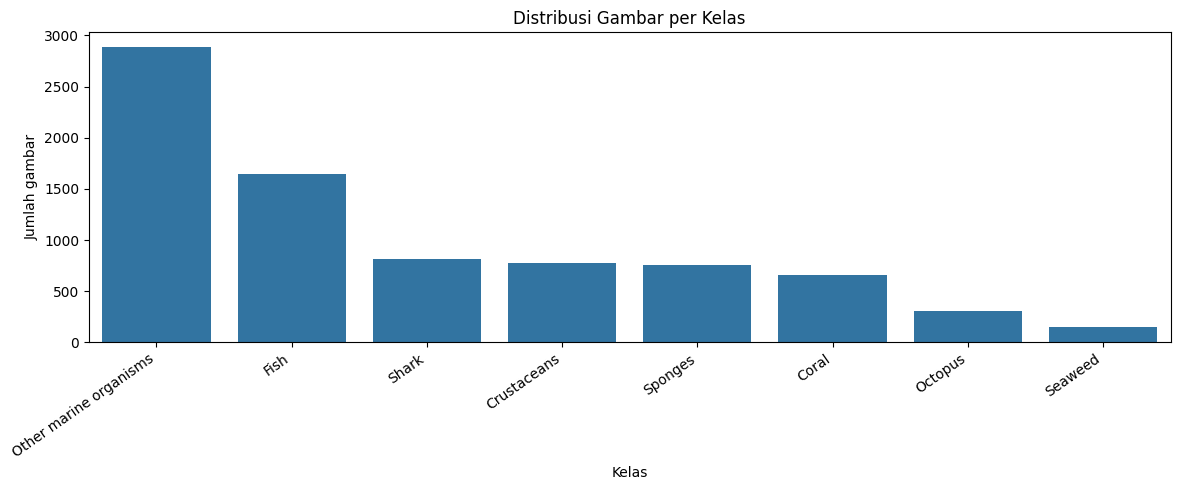

Proporsi data per kelas:


,class_name,image_count,proportion
0,Other marine organisms,2886,36.2%
1,Fish,1648,20.6%
2,Shark,818,10.2%
3,Crustaceans,773,9.7%
4,Sponges,751,9.4%
5,Coral,654,8.2%
6,Octopus,303,3.8%
7,Seaweed,149,1.9%


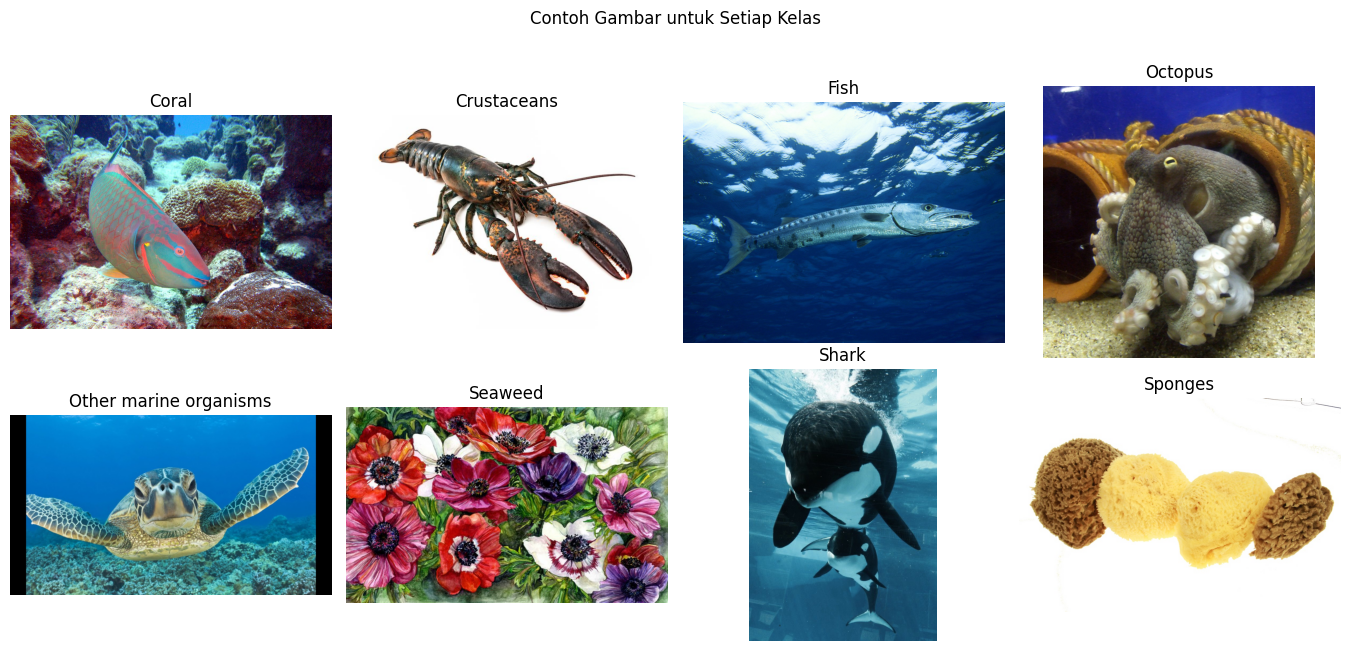

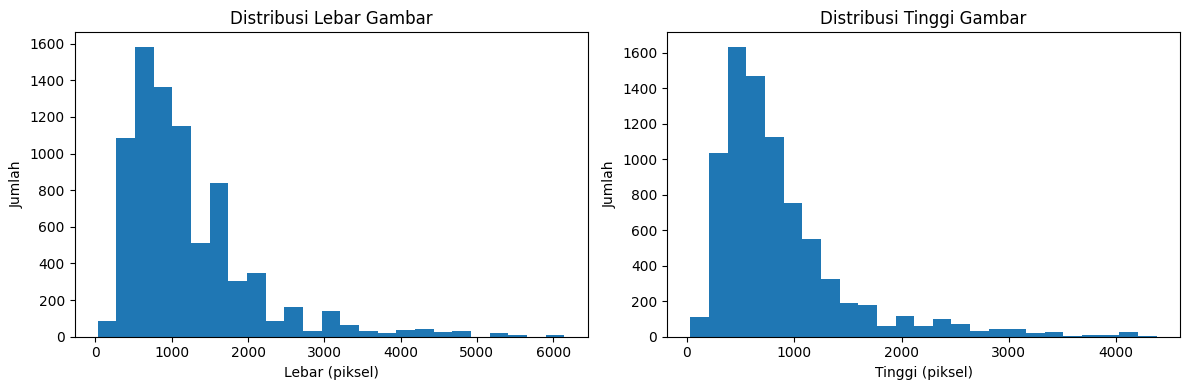

In [ ]:
if LABELS_AVAILABLE and len(df) > 0:
    class_counts = df["label"].value_counts().sort_values(ascending=False)
    class_dist_df = class_counts.rename_axis("class_name").reset_index(name="image_count")
    class_dist_df.to_csv(ARTIFACTS_DIR / "class_distribution.csv", index=False)

    plt.figure(figsize=(12, 5))
    sns.barplot(data=class_dist_df, x="class_name", y="image_count")
    plt.title("Distribusi Gambar per Kelas")
    plt.xlabel("Kelas")
    plt.ylabel("Jumlah gambar")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

    print("Proporsi data per kelas:")
    display((class_dist_df.assign(proportion=class_dist_df["image_count"] / class_dist_df["image_count"].sum())
             .sort_values("image_count", ascending=False)
             .style.format({"proportion": "{:.1%}"})))

    ncols = 4
    classes_to_show = sorted(df["label"].unique())
    nrows = int(np.ceil(len(classes_to_show) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.4, nrows * 3.2))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, class_name in zip(axes, classes_to_show):
        sample_path = df.loc[df["label"] == class_name, "filepath"].sample(1, random_state=SEED).iloc[0]
        with Image.open(sample_path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
        ax.set_title(class_name)
        ax.axis("off")
    plt.suptitle("Contoh Gambar untuk Setiap Kelas", y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print("EDA distribusi kelas dilewati karena label kelas belum tersedia.")

if not IMG_META_DF.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(IMG_META_DF["width"], bins=25)
    axes[0].set_title("Distribusi Lebar Gambar")
    axes[0].set_xlabel("Lebar (piksel)")
    axes[0].set_ylabel("Jumlah")
    axes[1].hist(IMG_META_DF["height"], bins=25)
    axes[1].set_title("Distribusi Tinggi Gambar")
    axes[1].set_xlabel("Tinggi (piksel)")
    axes[1].set_ylabel("Jumlah")
    plt.tight_layout()
    plt.show()

In [ ]:
SPLIT_READY = False
if LABELS_AVAILABLE:
    modeling_df = df[["filepath", "label"] + (["split"] if "split" in df.columns else [])].copy()
    modeling_df["label"] = modeling_df["label"].astype(str).str.strip()
    modeling_df = modeling_df[modeling_df["label"].ne("") & modeling_df["label"].ne("nan")].copy()

    counts = modeling_df["label"].value_counts()
    rare_classes = counts[counts < 3]
    if not rare_classes.empty:
        print("Kelas dengan kurang dari 3 gambar dikeluarkan dari modeling:")
        display(rare_classes.rename("image_count").to_frame())
        modeling_df = modeling_df[~modeling_df["label"].isin(rare_classes.index)].copy()

    if modeling_df["label"].nunique() < 2:
        print("Training tidak bisa dilakukan: diperlukan minimal 2 kelas dengan label yang valid.")
    else:
        label_encoder = LabelEncoder()
        label_encoder.fit(modeling_df["label"])
        CLASS_NAMES = list(label_encoder.classes_)
        modeling_df["label_id"] = label_encoder.transform(modeling_df["label"])

        def _safe_split(frame, test_size, random_state=SEED):
            y = frame["label_id"]
            stratify_values = y if y.value_counts().min() >= 2 else None
            try:
                return train_test_split(
                    frame, test_size=test_size, random_state=random_state,
                    stratify=stratify_values
                )
            except ValueError:
                print("Peringatan: stratified split tidak memungkinkan untuk jumlah data ini; memakai split acak.")
                return train_test_split(frame, test_size=test_size, random_state=random_state)

        train_df = val_df = test_df = None
        usable_split_values = set()
        if "split" in modeling_df.columns:
            modeling_df["split_norm"] = modeling_df["split"].astype(str).str.lower().map(
                lambda x: SPLIT_ALIASES.get(x, x)
            )
            usable_split_values = set(modeling_df["split_norm"].unique())

        if {"train", "test"}.issubset(usable_split_values):
            train_pool = modeling_df[modeling_df["split_norm"] == "train"].copy()
            test_df = modeling_df[modeling_df["split_norm"] == "test"].copy()
            validation_pool = modeling_df[modeling_df["split_norm"] == "validation"].copy()
            if len(validation_pool) > 0:
                train_df, val_df = train_pool, validation_pool
            else:
                train_df, val_df = _safe_split(train_pool, test_size=0.15)
            print("Memakai folder/kolom split train dan test dari dataset.")
        else:

            train_pool, test_df = _safe_split(modeling_df, test_size=0.20)
            train_df, val_df = _safe_split(train_pool, test_size=0.15)
            print("Membuat split stratified baru (train/validation/test).")


        train_labels = set(train_df["label_id"].unique())
        unseen_classes = [CLASS_NAMES[i] for i in range(len(CLASS_NAMES)) if i not in train_labels]
        if unseen_classes:
            print("Kelas tanpa contoh di train dikeluarkan agar output model konsisten:", unseen_classes)
            allowed_ids = train_labels
            train_df = train_df[train_df["label_id"].isin(allowed_ids)].copy()
            val_df = val_df[val_df["label_id"].isin(allowed_ids)].copy()
            test_df = test_df[test_df["label_id"].isin(allowed_ids)].copy()
            CLASS_NAMES = [name for idx, name in enumerate(CLASS_NAMES) if idx in allowed_ids]
            remap = {old: new for new, old in enumerate(sorted(allowed_ids))}
            for split_frame in (train_df, val_df, test_df):
                split_frame["label_id"] = split_frame["label_id"].map(remap).astype(int)

        if min(len(train_df), len(val_df), len(test_df)) > 0 and len(CLASS_NAMES) >= 2:
            SPLIT_READY = True
            split_summary = pd.DataFrame({
                "split": ["train", "validation", "test"],
                "jumlah_gambar": [len(train_df), len(val_df), len(test_df)],
            })
            split_summary["proporsi_dari_data"] = split_summary["jumlah_gambar"] / (
                len(train_df) + len(val_df) + len(test_df)
            )
            display(split_summary.style.format({"proporsi_dari_data": "{:.1%}"}))
            print("Nama kelas:", CLASS_NAMES)
            print("Distribusi label pada train:")
            display(train_df["label"].value_counts().sort_index().rename("jumlah_train").to_frame())
        else:
            print("Training dilewati: ukuran train/validation/test atau jumlah kelas tidak mencukupi.")
else:
    print("Split dan preprocessing berlabel dilewati. Perbaiki sumber label pada cell 4 terlebih dahulu.")

Membuat split stratified baru (train/validation/test).


,split,jumlah_gambar,proporsi_dari_data
0,train,5427,68.0%
1,validation,958,12.0%
2,test,1597,20.0%


Nama kelas: ['Coral', 'Crustaceans', 'Fish', 'Octopus', 'Other marine organisms', 'Seaweed', 'Shark', 'Sponges']
Distribusi label pada train:


,jumlah_train
label,
Coral,444
Crustaceans,525
Fish,1120
Octopus,207
Other marine organisms,1963
Seaweed,101
Shark,556
Sponges,511


In [ ]:
if SPLIT_READY:
    AUTOTUNE = tf.data.AUTOTUNE

    def _load_and_preprocess_image(filepath, label):

        def _decode_with_pillow(path_tensor):
            path_value = path_tensor.numpy().decode("utf-8")
            with Image.open(path_value) as pil_image:
                pil_image = ImageOps.exif_transpose(pil_image).convert("RGB")
                return np.asarray(pil_image, dtype=np.uint8)

        image = tf.py_function(
            func=_decode_with_pillow,
            inp=[filepath],
            Tout=tf.uint8
        )
        image.set_shape([None, None, 3])


        image = tf.image.resize_with_pad(
            image,
            target_height=IMG_SIZE,
            target_width=IMG_SIZE,
            method="bilinear"
        )

        image = tf.cast(image, tf.float32) / 255.0
        label = tf.cast(label, tf.int32)
        return image, label

    def make_dataset(frame, training=False):
        paths = frame["filepath"].astype(str).to_numpy()
        labels = frame["label_id"].to_numpy(dtype=np.int32)

        ds = tf.data.Dataset.from_tensor_slices((paths, labels))

        if training:
            ds = ds.shuffle(
                buffer_size=min(len(frame), 2048),
                seed=SEED,
                reshuffle_each_iteration=True
            )

        ds = ds.map(
            _load_and_preprocess_image,
            num_parallel_calls=AUTOTUNE
        )
        ds = ds.batch(BATCH_SIZE)
        ds = ds.prefetch(AUTOTUNE)
        return ds

    train_ds = make_dataset(train_df, training=True)
    val_ds = make_dataset(val_df, training=False)
    test_ds = make_dataset(test_df, training=False)

    print("Pipeline dataset siap.")
    print("Ukuran input:", IMG_SIZE, "x", IMG_SIZE)
    print("Batch size:", BATCH_SIZE)
    print("Batch train:", tf.data.experimental.cardinality(train_ds).numpy())
else:
    print("Pipeline TensorFlow dilewati karena split berlabel belum siap.")


Pipeline dataset siap.
Ukuran input: 160 x 160
Batch size: 16
Batch train: 340


In [ ]:
MODEL_PATH = ARTIFACTS_DIR / "oceanic_cnn.keras"
HEAD_BEST_PATH = ARTIFACTS_DIR / "mobilenetv2_head_best.keras"
FINE_BEST_PATH = ARTIFACTS_DIR / "mobilenetv2_finetune_best.keras"

CLASS_WEIGHT_MODE = "mild"

if SPLIT_READY:
    data_augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.08),
    ], name="data_augmentation")

    backbone = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    backbone_layer_name = backbone.name
    backbone.trainable = False

    inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image_input"
    )

    x = data_augmentation(inputs)

    x = layers.Rescaling(
        scale=2.0,
        offset=-1.0,
        name="mobilenet_input_scaling"
    )(x)

    x = backbone(x, training=False)
    x = layers.Activation("linear", name="last_conv")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(
        len(CLASS_NAMES),
        activation="softmax",
        name="class_probabilities"
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name="oceanic_life_mobilenetv2"
    )

    class_weight_dict = None

    if CLASS_WEIGHT_MODE == "mild":
        counts = (
            train_df["label_id"]
            .value_counts()
            .reindex(range(len(CLASS_NAMES)), fill_value=0)
        )

        if (counts == 0).any():
            raise ValueError(
                "Ada kelas yang tidak muncul pada train set; "
                "periksa kembali pembagian data."
            )

        raw_weights = (
            len(train_df) / (len(CLASS_NAMES) * counts.astype(float))
        ) ** 0.5

        weighted_mean = np.average(
            raw_weights.to_numpy(),
            weights=counts.to_numpy()
        )
        raw_weights = raw_weights / weighted_mean

        class_weight_dict = {
            int(class_id): float(raw_weights.loc[class_id])
            for class_id in range(len(CLASS_NAMES))
        }

    elif CLASS_WEIGHT_MODE == "none":
        class_weight_dict = None
    else:
        raise ValueError("CLASS_WEIGHT_MODE harus 'none' atau 'mild'.")

    print("Class weight mode:", CLASS_WEIGHT_MODE)
    print("Class weights:", class_weight_dict)

    class ValidationMacroF1(keras.callbacks.Callback):
        def __init__(self, validation_dataset, validation_labels, n_classes):
            super().__init__()
            self.validation_dataset = validation_dataset
            self.validation_labels = np.asarray(validation_labels)
            self.n_classes = n_classes

        def on_epoch_end(self, epoch, logs=None):
            if logs is None:
                logs = {}

            probabilities = self.model.predict(
                self.validation_dataset,
                verbose=0
            )
            predictions = np.argmax(probabilities, axis=1)

            score = f1_score(
                self.validation_labels,
                predictions,
                labels=list(range(self.n_classes)),
                average="macro",
                zero_division=0
            )
            logs["val_macro_f1"] = float(score)
            print(f" — val_macro_f1: {score:.4f}")

    val_macro_f1 = ValidationMacroF1(
        val_ds,
        val_df["label_id"].to_numpy(dtype=int),
        len(CLASS_NAMES)
    )

    def build_callbacks(checkpoint_path):
        return [
            val_macro_f1,
            keras.callbacks.ModelCheckpoint(
                filepath=str(checkpoint_path),
                monitor="val_macro_f1",
                mode="max",
                save_best_only=True,
                verbose=1
            ),
            keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.3,
                patience=2,
                min_lr=1e-6,
                verbose=1
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_macro_f1",
                mode="max",
                patience=4,
                restore_best_weights=True,
                verbose=1
            ),
        ]

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=3e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print("\n=== Tahap 1: training classifier head ===")
    history_head = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        callbacks=build_callbacks(HEAD_BEST_PATH),
        class_weight=class_weight_dict,
        verbose=1
    )

    if not HEAD_BEST_PATH.exists():
        raise RuntimeError(
            "Checkpoint tahap 1 tidak terbentuk. Periksa output training."
        )

    model = keras.models.load_model(HEAD_BEST_PATH)

    backbone = model.get_layer(backbone_layer_name)
    backbone.trainable = True

    for layer in backbone.layers[:-30]:
        layer.trainable = False

    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print("\n=== Tahap 2: fine-tuning layer terakhir ===")
    history_fine = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=6,
        callbacks=build_callbacks(FINE_BEST_PATH),
        class_weight=class_weight_dict,
        verbose=1
    )


    head_scores = history_head.history.get("val_macro_f1", [])
    fine_scores = history_fine.history.get("val_macro_f1", [])

    best_head_score = max(head_scores) if head_scores else -1.0
    best_fine_score = max(fine_scores) if fine_scores else -1.0

    if FINE_BEST_PATH.exists() and best_fine_score > best_head_score:
        selected_checkpoint = FINE_BEST_PATH
        selected_stage = "fine-tuning"
        selected_score = best_fine_score
    else:
        selected_checkpoint = HEAD_BEST_PATH
        selected_stage = "classifier head"
        selected_score = best_head_score

    model = keras.models.load_model(selected_checkpoint)
    model.save(MODEL_PATH)

    print("\nCheckpoint terpilih:", selected_stage)
    print(f"Validation macro-F1 terbaik: {selected_score:.4f}")
    print("Model final disimpan ke:", MODEL_PATH)


    history_frames = []
    epoch_offset = 0

    for stage_name, stage_history in [
        ("head", history_head),
        ("fine_tuning", history_fine)
    ]:
        stage_frame = pd.DataFrame(stage_history.history)
        if not stage_frame.empty:
            stage_frame.insert(
                0,
                "epoch",
                np.arange(
                    epoch_offset + 1,
                    epoch_offset + len(stage_frame) + 1
                )
            )
            stage_frame.insert(1, "stage", stage_name)
            history_frames.append(stage_frame)
            epoch_offset += len(stage_frame)

    history_df = pd.concat(
        history_frames,
        ignore_index=True
    )
    history_df.to_csv(
        ARTIFACTS_DIR / "training_history.csv",
        index=False
    )

    with open(ARTIFACTS_DIR / "classes.json", "w", encoding="utf-8") as f:
        json.dump(CLASS_NAMES, f, ensure_ascii=False, indent=2)

    with open(ARTIFACTS_DIR / "config.json", "w", encoding="utf-8") as f:
        json.dump(
            {
                "image_size": IMG_SIZE,
                "class_names": CLASS_NAMES,
                "architecture": "MobileNetV2",
                "class_weight_mode": CLASS_WEIGHT_MODE,
                "label_source": label_source
            },
            f,
            ensure_ascii=False,
            indent=2
        )

    display(history_df.tail(10))
else:
    print("Training CNN dilewati karena label/split belum siap.")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Class weight mode: mild
Class weights: {0: 1.338786759605005, 1: 1.2311847910010747, 2: 0.842934603110715, 3: 1.9607296711094644, 4: 0.6367115731431472, 5: 2.8069986694081805, 6: 1.196369955034534, 7: 1.247936374494578}

=== Tahap 1: training classifier head ===
Epoch 1/10


C:\Users\advan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 64/340 ━━━━━━━━━━━━━━━━━━━━ 2:07 461ms/step - accuracy: 0.4561 - loss: 1.5818

C:\Users\advan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\PIL\Image.py:996: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


340/340 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 0.6569 - loss: 0.9746 — val_macro_f1: 0.7852

Epoch 1: val_macro_f1 improved from None to 0.78524, saving model to d:\Tugas Analisis Big Data\2\artifacts\mobilenetv2_head_best.keras

Epoch 1: finished saving model to d:\Tugas Analisis Big Data\2\artifacts\mobilenetv2_head_best.keras
340/340 ━━━━━━━━━━━━━━━━━━━━ 171s 478ms/step - accuracy: 0.6569 - loss: 0.9746 - val_accuracy: 0.8111 - val_loss: 0.5570 - val_macro_f1: 0.7852 - learning_rate: 3.0000e-04
Epoch 2/10
 24/340 ━━━━━━━━━━━━━━━━━━━━ 1:50 350ms/step - accuracy: 0.8333 - loss: 0.5170

C:\Users\advan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\PIL\Image.py:996: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


... (28 outputs left out)

340/340 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.9952 - loss: 0.0156 — val_macro_f1: 0.9683

Epoch 5: val_macro_f1 improved from 0.96327 to 0.96833, saving model to d:\Tugas Analisis Big Data\2\artifacts\mobilenetv2_finetune_best.keras

Epoch 5: finished saving model to d:\Tugas Analisis Big Data\2\artifacts\mobilenetv2_finetune_best.keras
340/340 ━━━━━━━━━━━━━━━━━━━━ 132s 386ms/step - accuracy: 0.9952 - loss: 0.0156 - val_accuracy: 0.9729 - val_loss: 0.0844 - val_macro_f1: 0.9683 - learning_rate: 1.0000e-05
Epoch 6/6
  4/340 ━━━━━━━━━━━━━━━━━━━━ 2:50 509ms/step - accuracy: 1.0000 - loss: 0.0178

C:\Users\advan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\PIL\Image.py:996: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


340/340 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.9972 - loss: 0.0126 — val_macro_f1: 0.9794

Epoch 6: val_macro_f1 improved from 0.96833 to 0.97936, saving model to d:\Tugas Analisis Big Data\2\artifacts\mobilenetv2_finetune_best.keras

Epoch 6: finished saving model to d:\Tugas Analisis Big Data\2\artifacts\mobilenetv2_finetune_best.keras
340/340 ━━━━━━━━━━━━━━━━━━━━ 130s 381ms/step - accuracy: 0.9972 - loss: 0.0126 - val_accuracy: 0.9791 - val_loss: 0.0760 - val_macro_f1: 0.9794 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 6.

Checkpoint terpilih: fine-tuning
Validation macro-F1 terbaik: 0.9794
Model final disimpan ke: d:\Tugas Analisis Big Data\2\artifacts\oceanic_cnn.keras


,epoch,stage,accuracy,loss,val_accuracy,val_loss,val_macro_f1,learning_rate
6,7,head,0.980284,0.077345,0.942589,0.172008,0.947102,0.00030
7,8,head,0.983048,0.065238,0.948852,0.145020,0.953396,0.00030
8,9,head,0.986549,0.057346,0.942589,0.151263,0.942793,0.00030
9,10,head,0.988576,0.046238,0.956159,0.130930,0.956093,0.00030
10,11,fine_tuning,0.989128,0.036126,0.949896,0.149346,0.942643,0.00001
11,12,fine_tuning,0.990050,0.028988,0.963466,0.112391,0.958852,0.00001
12,13,fine_tuning,0.994104,0.022856,0.961378,0.109122,0.963271,0.00001
13,14,fine_tuning,0.995578,0.017627,0.964509,0.105014,0.959925,0.00001
14,15,fine_tuning,0.995209,0.015583,0.972860,0.084375,0.968333,0.00001
15,16,fine_tuning,0.997236,0.012551,0.979123,0.076019,0.979364,0.00001


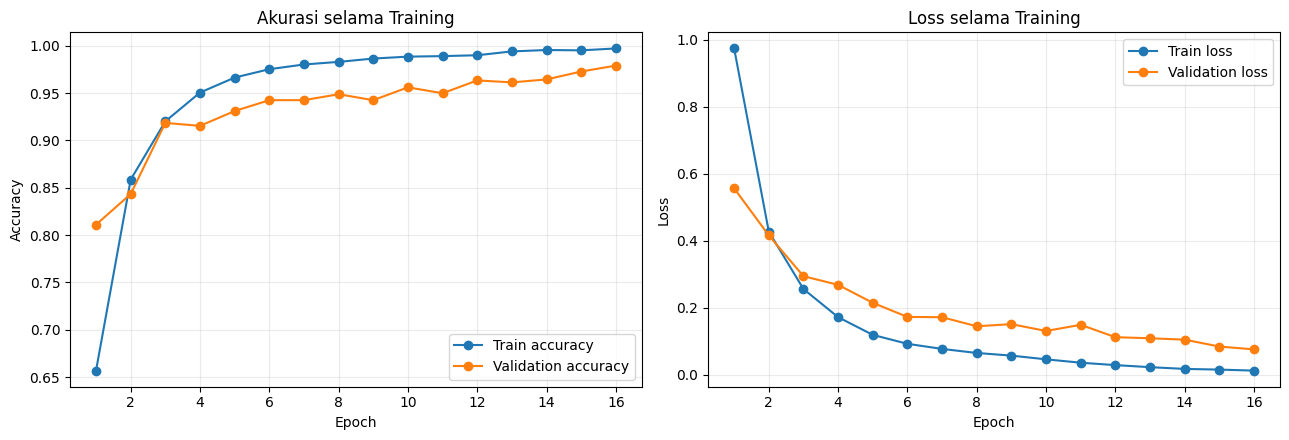

In [ ]:
if SPLIT_READY and (ARTIFACTS_DIR / "training_history.csv").exists():
    history_df = pd.read_csv(ARTIFACTS_DIR / "training_history.csv")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(history_df["epoch"], history_df["accuracy"], marker="o", label="Train accuracy")
    axes[0].plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation accuracy")
    axes[0].set_title("Akurasi selama Training")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(history_df["epoch"], history_df["loss"], marker="o", label="Train loss")
    axes[1].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
    axes[1].set_title("Loss selama Training")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Grafik training belum tersedia karena model belum dilatih.")

In [ ]:
EVALUATION_READY = False
if SPLIT_READY and MODEL_PATH.exists():
    y_true = test_df["label_id"].to_numpy(dtype=int)
    y_prob = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)
    confidence = np.max(y_prob, axis=1)

    metrics_summary = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "test_images": int(len(test_df)),
        "num_classes": int(len(CLASS_NAMES)),
    }
    display(pd.DataFrame([
        {"Metrik": "Accuracy", "Nilai": metrics_summary["accuracy"]},
        {"Metrik": "Precision (macro)", "Nilai": metrics_summary["precision_macro"]},
        {"Metrik": "Recall (macro)", "Nilai": metrics_summary["recall_macro"]},
        {"Metrik": "F1-score (macro)", "Nilai": metrics_summary["f1_macro"]},
        {"Metrik": "Precision (weighted)", "Nilai": metrics_summary["precision_weighted"]},
        {"Metrik": "Recall (weighted)", "Nilai": metrics_summary["recall_weighted"]},
        {"Metrik": "F1-score (weighted)", "Nilai": metrics_summary["f1_weighted"]},
    ]).style.format({"Nilai": "{:.4f}"}))

    report_dict = classification_report(
        y_true, y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    report_df = pd.DataFrame(report_dict).T.rename_axis("class_name").reset_index()
    report_df.to_csv(ARTIFACTS_DIR / "classification_report.csv", index=False)
    display(report_df)

    test_result_df = test_df[["filepath", "label"]].copy()
    test_result_df["true_label"] = [CLASS_NAMES[i] for i in y_true]
    test_result_df["predicted_label"] = [CLASS_NAMES[i] for i in y_pred]
    test_result_df["confidence"] = confidence
    test_result_df["correct"] = test_result_df["true_label"] == test_result_df["predicted_label"]
    test_result_df.to_csv(ARTIFACTS_DIR / "test_samples.csv", index=False)

    with open(ARTIFACTS_DIR / "metrics.json", "w", encoding="utf-8") as f:
        json.dump(metrics_summary, f, ensure_ascii=False, indent=2)

    dataset_summary = {
        "total_labeled_images": int(len(train_df) + len(val_df) + len(test_df)),
        "num_classes": int(len(CLASS_NAMES)),
        "class_names": CLASS_NAMES,
        "train_images": int(len(train_df)),
        "validation_images": int(len(val_df)),
        "test_images": int(len(test_df)),
        "train_ratio": float(len(train_df) / (len(train_df) + len(val_df) + len(test_df))),
        "validation_ratio": float(len(val_df) / (len(train_df) + len(val_df) + len(test_df))),
        "test_ratio": float(len(test_df) / (len(train_df) + len(val_df) + len(test_df))),
        "image_size": IMG_SIZE,
        "label_source": label_source,
    }
    with open(ARTIFACTS_DIR / "dataset_summary.json", "w", encoding="utf-8") as f:
        json.dump(dataset_summary, f, ensure_ascii=False, indent=2)

    EVALUATION_READY = True
    print("Analisis singkat:")
    print(f"Model benar pada {test_result_df['correct'].mean():.1%} gambar test.")
    hardest = report_df[report_df["class_name"].isin(CLASS_NAMES)].sort_values("f1-score").head(3)
    print("Kelas dengan F1-score terendah (perlu ditinjau):")
    display(hardest[["class_name", "precision", "recall", "f1-score", "support"]])
else:
    print("Evaluasi dilewati karena model belum tersedia.")

 45/100 ━━━━━━━━━━━━━━━━━━━━ 17s 312ms/step

C:\Users\advan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\PIL\Image.py:996: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 302ms/step


,Metrik,Nilai
0,Accuracy,0.9793
1,Precision (macro),0.9843
2,Recall (macro),0.9737
3,F1-score (macro),0.9786
4,Precision (weighted),0.9796
5,Recall (weighted),0.9793
6,F1-score (weighted),0.9792


,class_name,precision,recall,f1-score,support
0,Coral,0.948905,0.992366,0.970149,131.000000
1,Crustaceans,0.987013,0.980645,0.983819,155.000000
2,Fish,0.987768,0.978788,0.983257,330.000000
3,Octopus,1.000000,0.933333,0.965517,60.000000
4,Other marine organisms,0.971138,0.991334,0.981132,577.000000
5,Seaweed,1.000000,1.000000,1.000000,30.000000
6,Shark,0.993939,1.000000,0.996960,164.000000
7,Sponges,0.985612,0.913333,0.948097,150.000000
8,accuracy,0.979336,0.979336,0.979336,0.979336
9,macro avg,0.984297,0.973725,0.978616,1597.000000


Analisis singkat:
Model benar pada 97.9% gambar test.
Kelas dengan F1-score terendah (perlu ditinjau):


,class_name,precision,recall,f1-score,support
7,Sponges,0.985612,0.913333,0.948097,150.0
3,Octopus,1.000000,0.933333,0.965517,60.0
0,Coral,0.948905,0.992366,0.970149,131.0


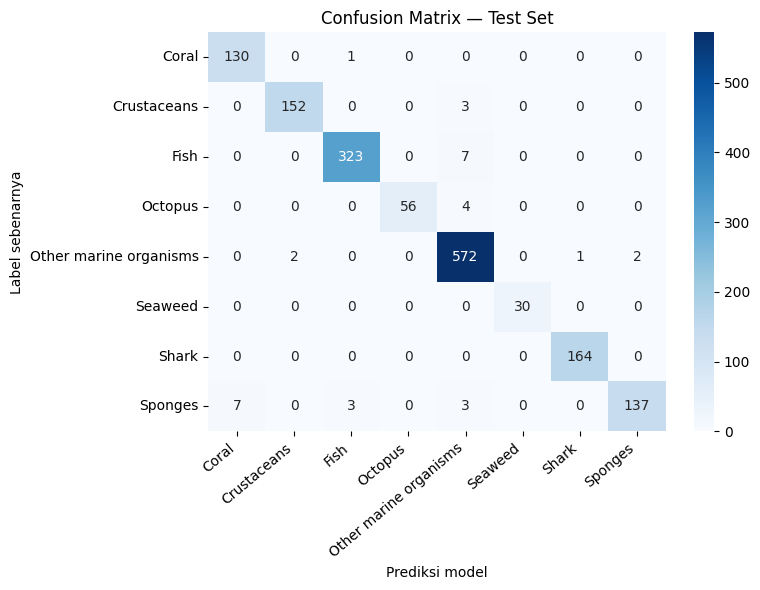

In [ ]:
if EVALUATION_READY:
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
    cm_df.to_csv(ARTIFACTS_DIR / "confusion_matrix.csv", index=True, index_label="actual_label")

    plt.figure(figsize=(max(8, len(CLASS_NAMES) * 0.9), max(6, len(CLASS_NAMES) * 0.7)))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", xticklabels=True, yticklabels=True)
    plt.title("Confusion Matrix — Test Set")
    plt.xlabel("Prediksi model")
    plt.ylabel("Label sebenarnya")
    plt.xticks(rotation=40, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Confusion matrix belum tersedia.")

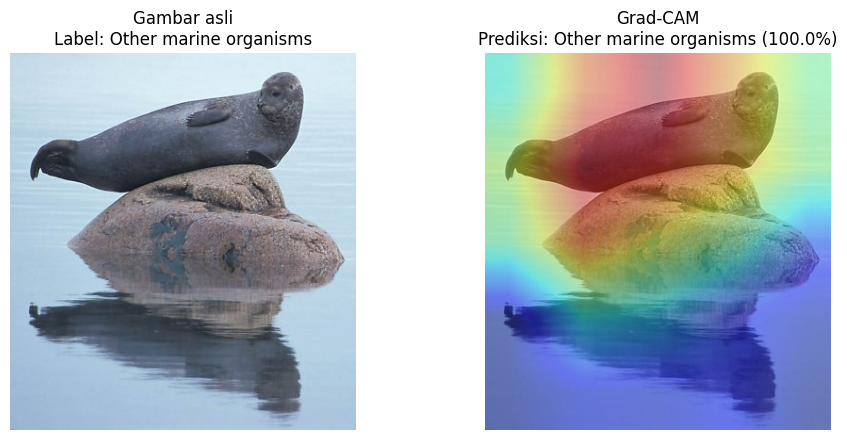

Interpretasi: area berwarna lebih hangat adalah area yang lebih kuat terkait dengan skor kelas yang diprediksi model. Tetap cocokkan dengan gambar asli dan label sebenarnya.


In [ ]:
def compute_gradcam(image_path, model_obj=None):
    if model_obj is None:
        model_obj = model
    original = ImageOps.exif_transpose(Image.open(image_path)).convert("RGB")
    resized = ImageOps.pad(original, (IMG_SIZE, IMG_SIZE), method=Image.Resampling.BILINEAR)
    image_array = np.asarray(resized, dtype=np.float32) / 255.0
    input_tensor = tf.convert_to_tensor(image_array[None, ...], dtype=tf.float32)

    grad_model = keras.Model(
        inputs=model_obj.inputs,
        outputs=[model_obj.get_layer("last_conv").output, model_obj.output],
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(input_tensor, training=False)
        predicted_index = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_index]
    gradients = tape.gradient(class_score, conv_outputs)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))
    conv_map = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_map * pooled_gradients, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    max_value = tf.reduce_max(heatmap)
    heatmap = tf.where(max_value > 0, heatmap / (max_value + 1e-8), heatmap)
    heatmap = heatmap.numpy()

    heatmap_square = Image.fromarray(np.uint8(255 * heatmap)).resize(
        (IMG_SIZE, IMG_SIZE),
        resample=Image.Resampling.BILINEAR
    )

    scale = min(IMG_SIZE / original.width, IMG_SIZE / original.height)
    content_w = max(1, int(round(original.width * scale)))
    content_h = max(1, int(round(original.height * scale)))
    left = (IMG_SIZE - content_w) // 2
    top = (IMG_SIZE - content_h) // 2

    heatmap_image = heatmap_square.crop(
        (left, top, left + content_w, top + content_h)
    ).resize(original.size, resample=Image.Resampling.BILINEAR)

    heatmap_array = np.asarray(heatmap_image, dtype=np.float32) / 255.0
    color_map = plt.get_cmap("jet")(heatmap_array)[..., :3]
    original_array = np.asarray(original, dtype=np.float32) / 255.0
    overlay = np.clip(0.60 * original_array + 0.40 * color_map, 0, 1)
    probs = predictions.numpy()[0]
    return original, overlay, probs


if EVALUATION_READY and len(test_df) > 0:
    sample_row = test_result_df.iloc[0]
    original, overlay, probs = compute_gradcam(sample_row["filepath"])
    pred_idx = int(np.argmax(probs))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    axes[0].imshow(original)
    axes[0].set_title(f"Gambar asli\nLabel: {sample_row['true_label']}")
    axes[0].axis("off")
    axes[1].imshow(overlay)
    axes[1].set_title(f"Grad-CAM\nPrediksi: {CLASS_NAMES[pred_idx]} ({probs[pred_idx]:.1%})")
    axes[1].axis("off")
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "gradcam_example.png", dpi=160, bbox_inches="tight")
    plt.show()
    print("Interpretasi: area berwarna lebih hangat adalah area yang lebih kuat terkait dengan skor kelas yang diprediksi model. Tetap cocokkan dengan gambar asli dan label sebenarnya.")
else:
    print("Contoh Grad-CAM belum tersedia.")